In [ ]:
import numpy as np
import pandas as pd
data = [
    ['sunny', 85, 85, 'false', 'no'],
    ['sunny', 80, 90, 'true', 'no'],
    ['overcast', 83, 78, 'false', 'yes'],
    ['rainy', 70, 96, 'false', 'yes'],
    ['rainy', 68, 80, 'false', 'yes'],

]

df = pd.DataFrame(data, columns=['outlook', 'temperature', 'humidity', 'wind', 'play'])
display(df)

,outlook,temperature,humidity,wind,play
0,sunny,85,85,false,no
1,sunny,80,90,true,no
2,overcast,83,78,false,yes
3,rainy,70,96,false,yes
4,rainy,68,80,false,yes


In [ ]:
import numpy as np
import pandas as pd


calculate_gini = lambda y: 1.0 - sum((np.sum(y == val) / len(y)) ** 2 for val in np.unique(y)) if len(y) > 0 else 0.0

get_best_split_for_col = lambda df_node, feature, target: (
    sorted(
        [
            (

                calculate_gini(df_node[target]) - (
                    (len(df_node[df_node[feature] <= val]) / len(df_node)) * calculate_gini(df_node[df_node[feature] <= val][target]) +
                    (len(df_node[df_node[feature] > val]) / len(df_node)) * calculate_gini(df_node[df_node[feature] > val][target])
                ),
                val,
                df_node[feature] <= val,
                df_node[feature] > val
            )
            for val in [
                (sorted(df_node[feature].unique())[i] + sorted(df_node[feature].unique())[i+1]) / 2.0
                for i in range(len(df_node[feature].unique()) - 1)
            ]
        ],
        key=lambda x: x[0],
        reverse=True
    )[0] if len(df_node[feature].unique()) > 1 else (0.0, None, None, None)
)



target_col = 'play'
feature_cols = ['temperature', 'humidity']
max_depth = 3


tree_nodes = []
node_queue = [(df, None, 'root', 0)]

while len(node_queue) > 0:
    current_df, parent_idx, direction, depth = node_queue.pop(0)
    current_idx = len(tree_nodes)


    unique_labels = current_df[target_col].unique()
    is_leaf = len(unique_labels) == 1 or depth >= max_depth
    majority_class = current_df[target_col].value_counts().idxmax()

    if is_leaf:
        node_info = {
            'index': current_idx,
            'is_leaf': True,
            'class': majority_class,
            'samples': len(current_df)
        }
        tree_nodes.append(node_info)
    else:

        splits = [get_best_split_for_col(current_df, col, target_col) + (col,) for col in feature_cols]
        best_split = max(splits, key=lambda x: x[0])
        best_gain, best_val, left_mask, right_mask, best_feature = best_split

        if best_gain <= 0:
            node_info = {
                'index': current_idx,
                'is_leaf': True,
                'class': majority_class,
                'samples': len(current_df)
            }
            tree_nodes.append(node_info)
        else:
            node_info = {
                'index': current_idx,
                'is_leaf': False,
                'feature': best_feature,
                'threshold': best_val,
                'samples': len(current_df),
                'left_child': None,
                'right_child': None
            }
            tree_nodes.append(node_info)


            node_queue.append((current_df[left_mask], current_idx, 'left', depth + 1))
            node_queue.append((current_df[right_mask], current_idx, 'right', depth + 1))


    if parent_idx is not None:
        if direction == 'left':
            tree_nodes[parent_idx]['left_child'] = current_idx
        elif direction == 'right':
            tree_nodes[parent_idx]['right_child'] = current_idx


print("=== INDUCED DECISION TREE (No 'def' functions) ===")
for node in tree_nodes:
    if node['is_leaf']:
        print(f"Node {node['index']}: LEAF [Samples: {node['samples']}, Predict Class: '{node['class']}']")
    else:
        print(f"Node {node['index']}: SPLIT [Samples: {node['samples']}, Feature: {node['feature']} <= {node['threshold']:.2f}, Left Child: Node {node['left_child']}, Right Child: Node {node['right_child']}]")

=== INDUCED DECISION TREE (No 'def' functions) ===
Node 0: SPLIT [Samples: 5, Feature: temperature <= 75.00, Left Child: Node 1, Right Child: Node 2]
Node 1: LEAF [Samples: 2, Predict Class: 'yes']
Node 2: SPLIT [Samples: 3, Feature: humidity <= 81.50, Left Child: Node 3, Right Child: Node 4]
Node 3: LEAF [Samples: 1, Predict Class: 'yes']
Node 4: LEAF [Samples: 2, Predict Class: 'no']


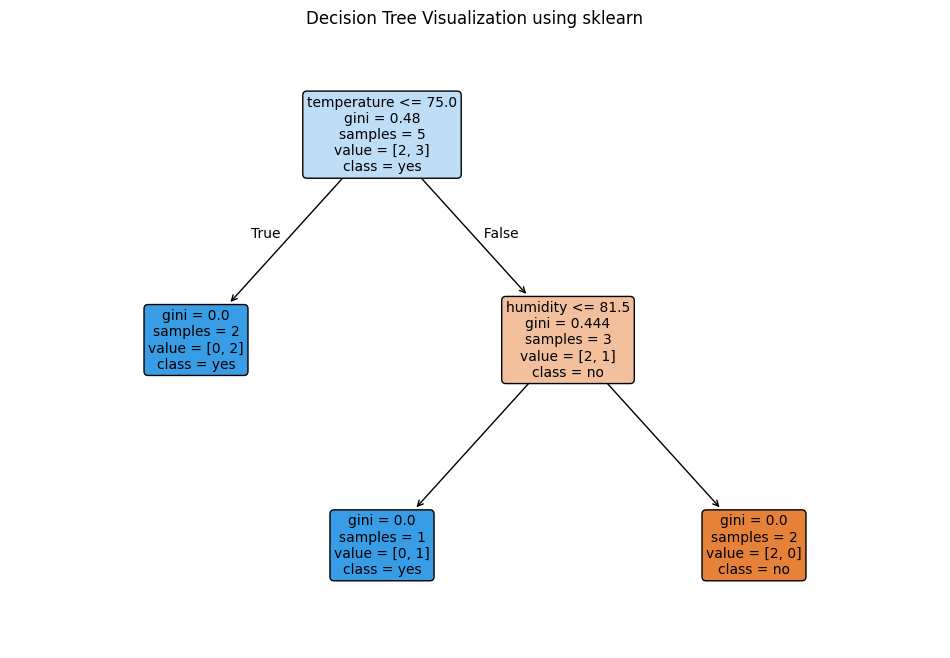

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder

# --- 1. Prepare Data ---
le = LabelEncoder()
y = le.fit_transform(df['play'])
X = df[['temperature', 'humidity']]

# --- 2. Fit the Decision Tree ---
clf = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
clf.fit(X, y)

# --- 3. Plot the Decision Tree ---
fig = plt.figure(figsize=(12, 8))
plot_tree(
    clf,
    feature_names=list(X.columns),
    class_names=list(le.classes_),
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization using sklearn")
plt.show()